Opis problema

Rak dojke jedan je od najčešćih zloćudnih tumora kod žena, a rana i točna dijagnoza značajno povećava šanse za uspješno liječenje. Problem koji se rješava u ovom projektu je binarna klasifikacija: na temelju izmjerenih karakteristika staničnih jezgri dobivenih iz digitalizirane slike tankoigličnog aspirata (FNA) tumora dojke, potrebno je predvidjeti je li tumor zloćudan (malignant) ili dobroćudan (benign).

Ovakav model ima praktičnu vrijednost jer može poslužiti kao pomoćni alat liječnicima pri brzoj, jeftinoj i objektivnoj procjeni prirode tumora, uz napomenu da konačnu dijagnozu uvijek donosi liječnik.



Ciljevi projekta

Prikupiti i pripremiti javno dostupan skup podataka o karakteristikama tumora dojke.
Provesti istraživačku analizu podataka (EDA) i odabrati najrelevantnije značajke za klasifikaciju.
Implementirati i usporediti nekoliko različitih klasifikacijskih modela (logistička regresija, SVM, slučajna šuma).
Ocijeniti robusnost modela pomoću kros-validacije.
Evaluirati performanse modela pomoću standardnih metrika za klasifikaciju (točnost, preciznost, odziv, F1 mjera, matrica zabune) i odabrati najbolji model.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              ConfusionMatrixDisplay)

sns.set_style("whitegrid")
np.random.seed(42)

# Učitavanje podataka
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target  # 0 = malignant, 1 = benign

print(f"Broj uzoraka: {df.shape[0]}, broj značajki: {df.shape[1] - 1}")
df.head()

Broj uzoraka: 569, broj značajki: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
# Provjera nedostajućih vrijednosti
print("Nedostajuće vrijednosti po stupcu:")
print(df.isnull().sum().sum(), "ukupno nedostajućih vrijednosti u cijelom skupu")

# Kodiranje kategorijske varijable (dijagnoza) - eksplicitno mapiranje naziva klasa u brojeve
label_map = {0: 'malignant', 1: 'benign'}
df['diagnosis'] = df['target'].map(label_map)
print("\nRaspodjela klasa:")
print(df['diagnosis'].value_counts())

# Odvajanje značajki (X) i ciljne varijable (y)
X = df[data.feature_names]
y = df['target']

# Podjela na train/test prije normalizacije (kako bismo izbjegli curenje podataka)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalizacija (standardizacija) značajki
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("\nPrimjer podataka prije normalizacije:")
print(X_train.iloc[:2, :4])
print("\nPrimjer podataka nakon normalizacije:")
print(X_train_scaled.iloc[:2, :4])

Nedostajuće vrijednosti po stupcu:
0 ukupno nedostajućih vrijednosti u cijelom skupu

Raspodjela klasa:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Primjer podataka prije normalizacije:
     mean radius  mean texture  mean perimeter  mean area
546        10.32         16.35           65.31      324.9
432        20.18         19.54          133.80     1250.0

Primjer podataka nakon normalizacije:
     mean radius  mean texture  mean perimeter  mean area
546    -1.072001     -0.658425       -1.088080  -0.939274
432     1.748743      0.066502        1.751157   1.745559


/tmp/ipykernel_1876/647441002.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=df, palette='pastel')


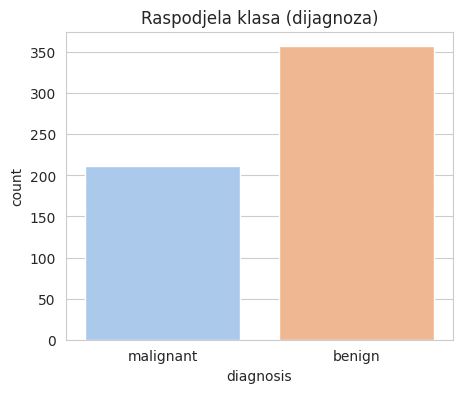

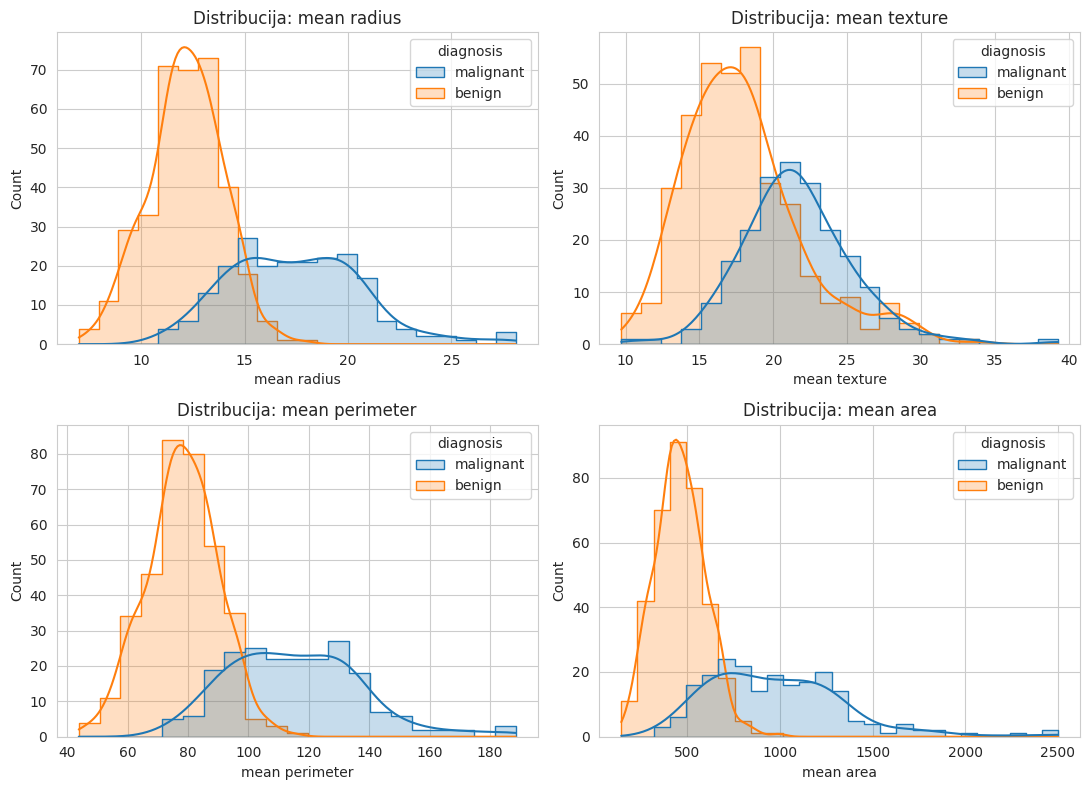

In [5]:
# Raspodjela klasa
plt.figure(figsize=(5,4))
sns.countplot(x='diagnosis', data=df, palette='pastel')
plt.title('Raspodjela klasa (dijagnoza)')
plt.show()

# Distribucije nekoliko ključnih značajki po klasi
key_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.flatten(), key_features):
    sns.histplot(data=df, x=feat, hue='diagnosis', kde=True, ax=ax, element='step')
    ax.set_title(f'Distribucija: {feat}')
plt.tight_layout()
plt.show()

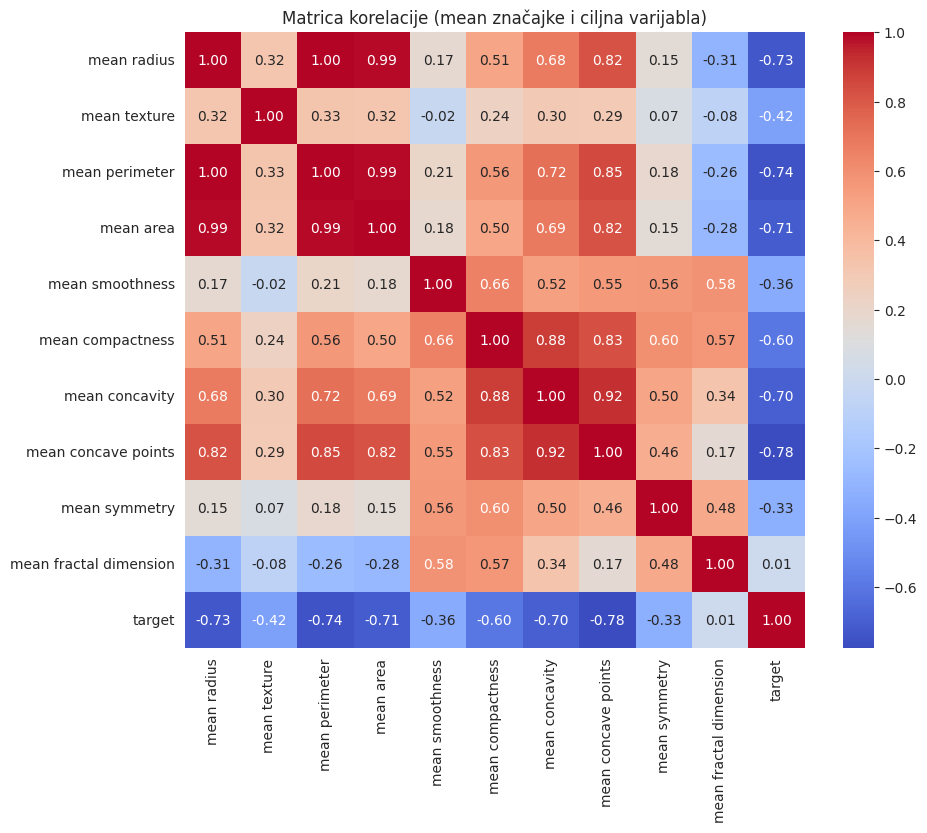

Korelacija svake 'mean' značajke s ciljnom varijablom (target):
mean concave points      -0.776614
mean perimeter           -0.742636
mean radius              -0.730029
mean area                -0.708984
mean concavity           -0.696360
mean compactness         -0.596534
mean texture             -0.415185
mean smoothness          -0.358560
mean symmetry            -0.330499
mean fractal dimension    0.012838
target                    1.000000
Name: target, dtype: float64


In [6]:
# Matrica korelacije (prikazujemo podskup značajki radi preglednosti - 'mean' značajke)
mean_cols = [c for c in data.feature_names if c.startswith('mean')]
corr = df[mean_cols + ['target']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Matrica korelacije (mean značajke i ciljna varijabla)')
plt.show()

print("Korelacija svake 'mean' značajke s ciljnom varijablom (target):")
print(corr['target'].sort_values())

Top 10 odabranih značajki:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


/tmp/ipykernel_1876/1585742766.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_scores.head(10), y='feature', x='f_score', palette='viridis')


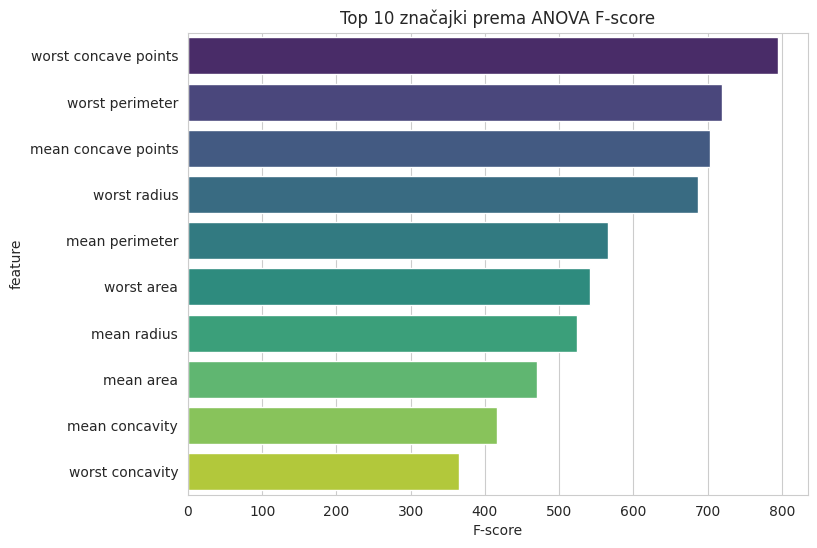

In [7]:
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X_train_scaled, y_train)

selected_mask = selector.get_support()
selected_features = X_train_scaled.columns[selected_mask].tolist()

feature_scores = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'f_score': selector.scores_
}).sort_values('f_score', ascending=False)

print("Top 10 odabranih značajki:")
print(selected_features)

plt.figure(figsize=(8, 6))
sns.barplot(data=feature_scores.head(10), y='feature', x='f_score', palette='viridis')
plt.title('Top 10 značajki prema ANOVA F-score')
plt.xlabel('F-score')
plt.show()

# Konačni skupovi podataka koje koristimo za modeliranje
X_train_final = X_train_scaled[selected_features]
X_test_final = X_test_scaled[selected_features]

In [8]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_final, y_train)
    trained_models[name] = model
    print(f"{name} istreniran.")

Logistic Regression istreniran.
SVM (RBF) istreniran.
Random Forest istreniran.


Logistic Regression: mean accuracy = 0.9473  (std = 0.0162)
SVM (RBF): mean accuracy = 0.9473  (std = 0.0162)
Random Forest: mean accuracy = 0.9473  (std = 0.0213)


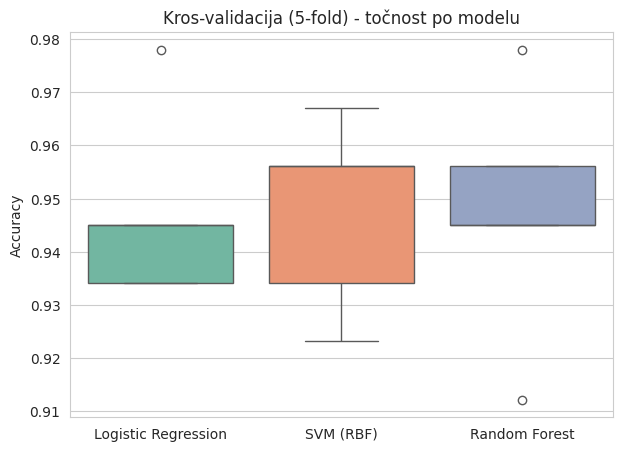

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train_final, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name}: mean accuracy = {scores.mean():.4f}  (std = {scores.std():.4f})")

cv_df = pd.DataFrame(cv_results)
plt.figure(figsize=(7,5))
sns.boxplot(data=cv_df, palette='Set2')
plt.title('Kros-validacija (5-fold) - točnost po modelu')
plt.ylabel('Accuracy')
plt.show()

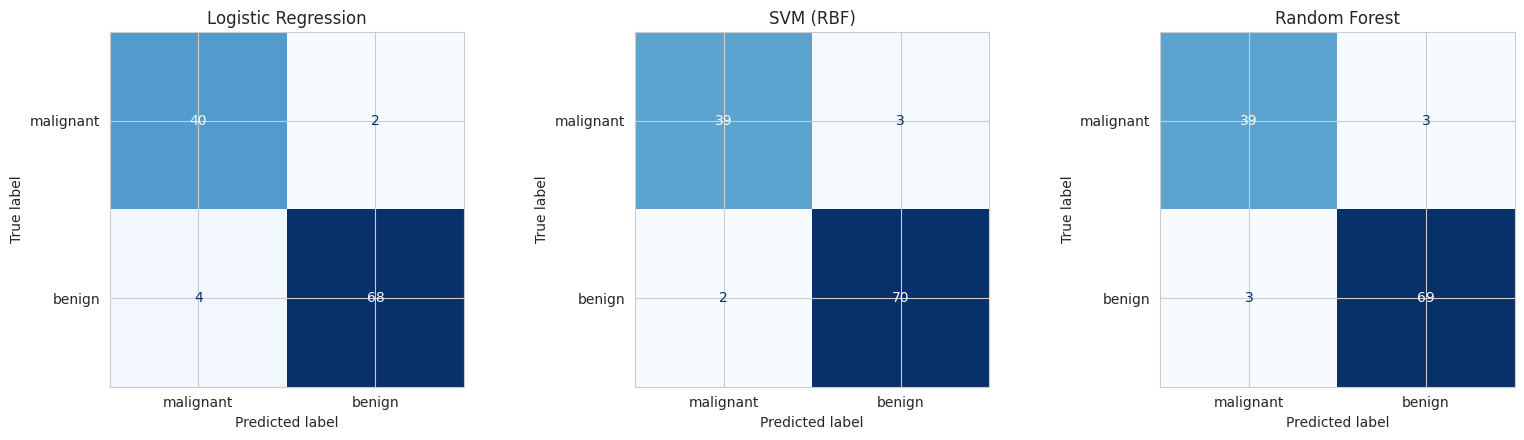

                     Accuracy  Precision  Recall  F1-score
Model                                                     
Logistic Regression    0.9474     0.9714  0.9444    0.9577
SVM (RBF)              0.9561     0.9589  0.9722    0.9655
Random Forest          0.9474     0.9583  0.9583    0.9583


In [11]:
results = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, model) in zip(axes, trained_models.items()):
    y_pred = model.predict(X_test_final)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-score': f1})

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['malignant', 'benign'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results).set_index('Model')
print(results_df.round(4))

Usporedba modela (sortirano po F1-score):
                     Accuracy  Precision  Recall  F1-score
Model                                                     
SVM (RBF)              0.9561     0.9589  0.9722    0.9655
Random Forest          0.9474     0.9583  0.9583    0.9583
Logistic Regression    0.9474     0.9714  0.9444    0.9577


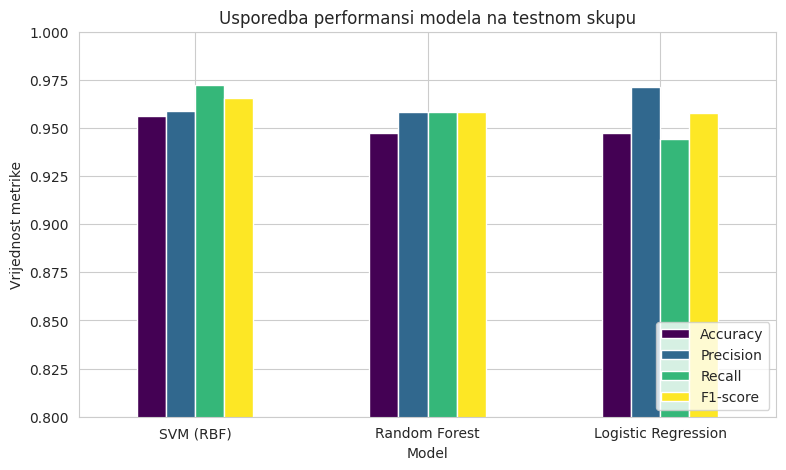


Najbolji model prema F1-score: SVM (RBF)

Detaljan izvještaj klasifikacije za najbolji model:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [12]:
results_df_sorted = results_df.sort_values('F1-score', ascending=False)
print("Usporedba modela (sortirano po F1-score):")
print(results_df_sorted.round(4))

results_df_sorted[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(
    kind='bar', figsize=(9, 5), colormap='viridis'
)
plt.title('Usporedba performansi modela na testnom skupu')
plt.ylabel('Vrijednost metrike')
plt.xticks(rotation=0)
plt.ylim(0.8, 1.0)
plt.legend(loc='lower right')
plt.show()

best_model_name = results_df_sorted.index[0]
print(f"\nNajbolji model prema F1-score: {best_model_name}")
print("\nDetaljan izvještaj klasifikacije za najbolji model:")
print(classification_report(y_test, trained_models[best_model_name].predict(X_test_final),
                             target_names=['malignant', 'benign']))